# Road Accident Severity Project


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import os
os.makedirs('charts', exist_ok=True)
print('Libraries ready')

Libraries ready


## 1. Load the data
load the CSV and check the first rows, sample rows, shape, summary, and severity counts.

In [2]:
df = pd.read_csv('indian_roads_dataset.csv')
print(df.head())
print(df.sample(5))
print(df.shape)
print(df.info())
print(df.describe(include='all').T)
print(df.columns.tolist())
print(df['accident_severity'].value_counts())

   accident_id   city  state   latitude  longitude        date   time  hour  \
0            5  Delhi  Delhi  28.799490  77.049666  2024-07-29  08:00     8   
1           24  Delhi  Delhi  28.528171  77.003017  2023-03-26  01:00     1   
2           25  Delhi  Delhi  28.631253  77.168852  2022-11-02  14:00    14   
3           29  Delhi  Delhi  28.494878  77.089734  2025-04-08  17:00    17   
4           34  Delhi  Delhi  28.767686  77.102505  2022-06-02  17:00    17   

  day_of_week  is_weekend  ... visibility  temperature  traffic_density  \
0      Monday           0  ...     medium           33           medium   
1      Sunday           1  ...     medium           23              low   
2   Wednesday           0  ...        low           19              low   
3     Tuesday           0  ...        low           22             high   
4    Thursday           0  ...       high           36             high   

           cause accident_severity  vehicles_involved casualties is_peak_h

Insight: severity has three classes (minor, major, fatal). The festival column is almost entirely empty (see the non-null counts above), so it is handled in the cleaning step.

## 2. Data cleaning

In [3]:
print('before', df.shape)
print(df.isnull().sum())
# Missing values: show the % missing per column, then drop every column that is more than 50% empty
missing_pct = (df.isnull().mean() * 100).round(2)
print(missing_pct[missing_pct > 0])
MISSING_LIMIT = 50
cols_to_drop = missing_pct[missing_pct > MISSING_LIMIT].index.tolist()
df = df.drop(columns=cols_to_drop)
print(f'Dropped (more than {MISSING_LIMIT}% missing):', cols_to_drop)

# Duplicate rows
n_dup = df.duplicated().sum()
df = df.drop_duplicates()
print('Duplicate rows removed:', n_dup)
df['city'] = df['city'].str.strip().str.title()
df['state'] = df['state'].str.strip()
df['weather'] = df['weather'].str.strip().str.lower()
df['cause'] = df['cause'].str.strip().str.lower()
df['road_type'] = df['road_type'].str.strip().str.lower()
df['visibility'] = df['visibility'].str.strip().str.lower()
df['day_of_week'] = df['day_of_week'].str.strip()
df['date'] = pd.to_datetime(df['date'])
print('after', df.shape)
print('Missing values left:', int(df.isnull().sum().sum()))

before (13559, 24)
accident_id              0
city                     0
state                    0
latitude                 0
longitude                0
date                     0
time                     0
hour                     0
day_of_week              0
is_weekend               0
road_type                0
lanes                    0
traffic_signal           0
weather                  0
visibility               0
temperature              0
traffic_density          0
cause                    0
accident_severity        0
vehicles_involved        0
casualties               0
is_peak_hour             0
festival             13480
risk_score               0
dtype: int64
festival    99.42
dtype: float64
Dropped (more than 50% missing): ['festival']
Duplicate rows removed: 0
after (13559, 23)
Missing values left: 0


Insight: festival was about 99% missing, so it was dropped instead of being filled in. No other column had missing values. Text fields were standardised and the date column was converted to datetime.

## 3. Feature engineering
create month, year, and time_of_day

In [4]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['hour'] = df['hour'].astype(int)
cond = [
    df['hour'].between(5, 11),
    df['hour'].between(12, 16),
    df['hour'].between(17, 20),
    df['hour'].between(21, 23) | (df['hour'] <= 4)
]
labels = ['Morning', 'Afternoon', 'Evening', 'Night']
df['time_of_day'] = np.select(cond, labels, default='Unknown')
assert (df['time_of_day'] != 'Unknown').all(), 'some hours were not assigned to a time of day'
print(df[['hour', 'time_of_day', 'year', 'month']].head())
print('Hours in each bucket:')
print(df.groupby('time_of_day')['hour'].nunique())

   hour time_of_day  year  month
0     8     Morning  2024      7
1     1       Night  2023      3
2    14   Afternoon  2022     11
3    17     Evening  2025      4
4    17     Evening  2022      6
Hours in each bucket:
time_of_day
Afternoon    5
Evening      4
Morning      7
Night        8
Name: hour, dtype: int64


Insight: the time-of-day buckets have different lengths (see the hour counts above), so raw counts per bucket are not comparable. Compare shares or per-hour averages instead.

## 4. Leakage check
Casualties are known only after the accident, and risk_score is calculated from other columns, so both stay out of the prediction model.

In [5]:
LEAKAGE_COLS = ['casualties', 'risk_score']   # outcome columns: they must stay out of the model
print(df.groupby('accident_severity')[LEAKAGE_COLS].mean().round(2))
print(df[['risk_score', 'casualties']].describe())

                   casualties  risk_score
accident_severity                        
fatal                    4.43        0.64
major                    3.03        0.46
minor                    1.00        0.28
         risk_score    casualties
count  13559.000000  13559.000000
mean       0.416601      2.396563
std        0.248380      1.734576
min        0.000000      0.000000
25%        0.230000      1.000000
50%        0.370000      2.000000
75%        0.630000      4.000000
max        1.000000      7.000000


Insight: both columns rise sharply with severity, which is exactly why they would leak the answer into a model. Section 9 checks in code that they are not among the model features.

## 5. EDA charts
load the main accident patterns and save them in the charts folder.

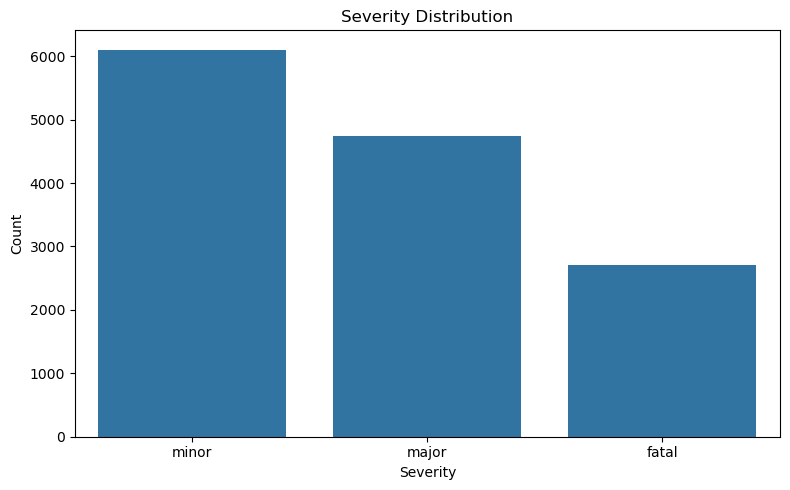

In [6]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='accident_severity', order=['minor', 'major', 'fatal'])
plt.title('Severity Distribution')
plt.xlabel('Severity')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('charts/severity_distribution.png')
plt.show()

Insight: minor accidents are the largest class (about 45%) and fatal the smallest (about 20%). This is a moderate imbalance, which is why the train/test split is stratified.

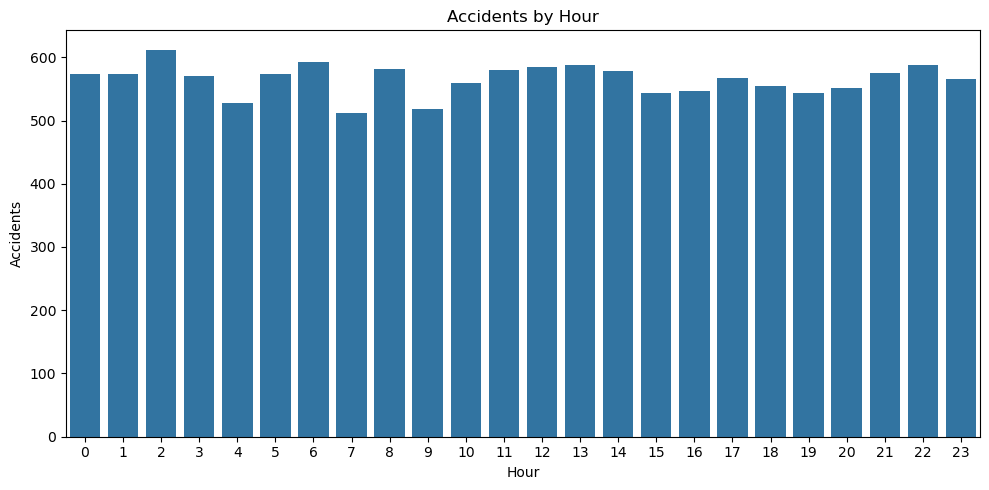

In [7]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='hour')
plt.title('Accidents by Hour')
plt.xlabel('Hour')
plt.ylabel('Accidents')
plt.tight_layout()
plt.savefig('charts/accidents_by_hour.png')
plt.show()

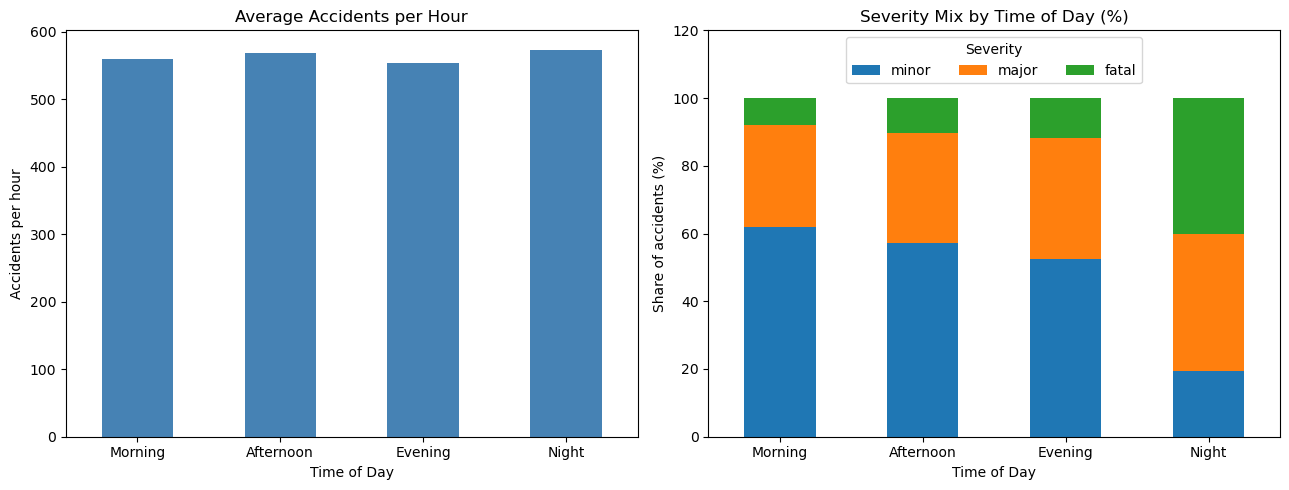

In [8]:
tod_order = ['Morning', 'Afternoon', 'Evening', 'Night']
hours_in_bucket = df.groupby('time_of_day')['hour'].nunique()
per_hour = (df['time_of_day'].value_counts() / hours_in_bucket).reindex(tod_order)
severity_mix = (pd.crosstab(df['time_of_day'], df['accident_severity'], normalize='index')
                  .loc[tod_order, ['minor', 'major', 'fatal']] * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
per_hour.plot(kind='bar', ax=axes[0], rot=0, color='steelblue')
axes[0].set_title('Average Accidents per Hour')
axes[0].set_xlabel('Time of Day')
axes[0].set_ylabel('Accidents per hour')
severity_mix.plot(kind='bar', stacked=True, ax=axes[1], rot=0)
axes[1].set_title('Severity Mix by Time of Day (%)')
axes[1].set_xlabel('Time of Day')
axes[1].set_ylabel('Share of accidents (%)')
axes[1].set_ylim(0, 120)
axes[1].legend(title='Severity', ncol=3, loc='upper center')
plt.tight_layout()
plt.savefig('charts/accidents_by_time_of_day.png')
plt.show()

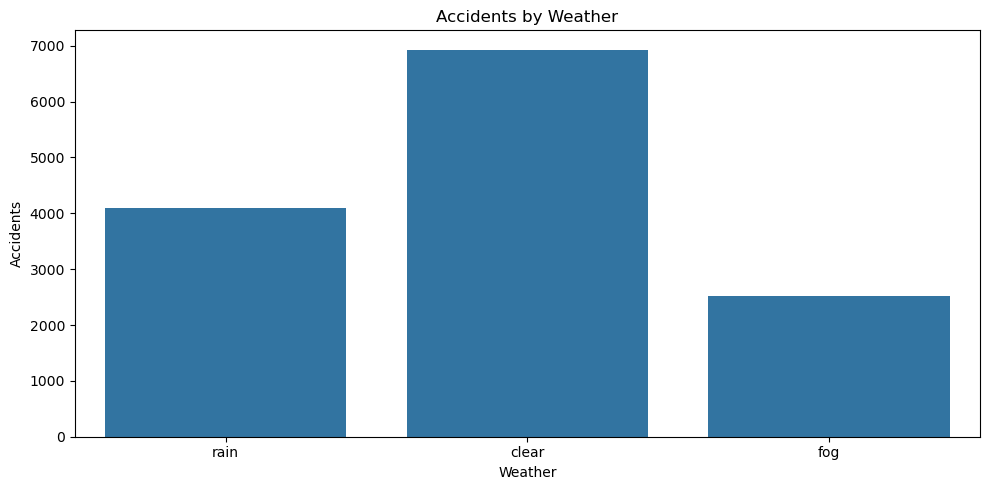

In [9]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='weather')
plt.title('Accidents by Weather')
plt.xlabel('Weather')
plt.ylabel('Accidents')
plt.tight_layout()
plt.savefig('charts/accidents_by_weather.png')
plt.show()

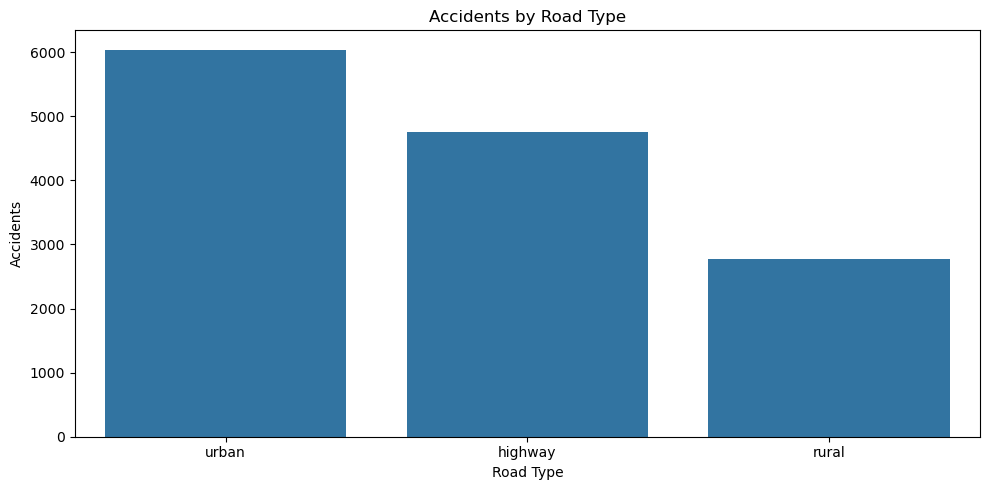

In [10]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='road_type')
plt.title('Accidents by Road Type')
plt.xlabel('Road Type')
plt.ylabel('Accidents')
plt.tight_layout()
plt.savefig('charts/accidents_by_road_type.png')
plt.show()

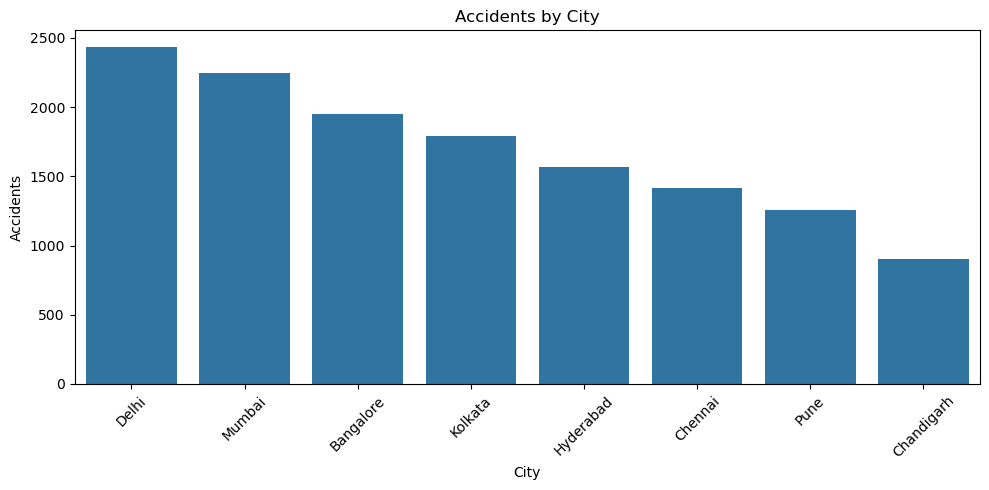

In [11]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='city')
plt.title('Accidents by City')
plt.xlabel('City')
plt.ylabel('Accidents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('charts/accidents_by_city.png')
plt.show()

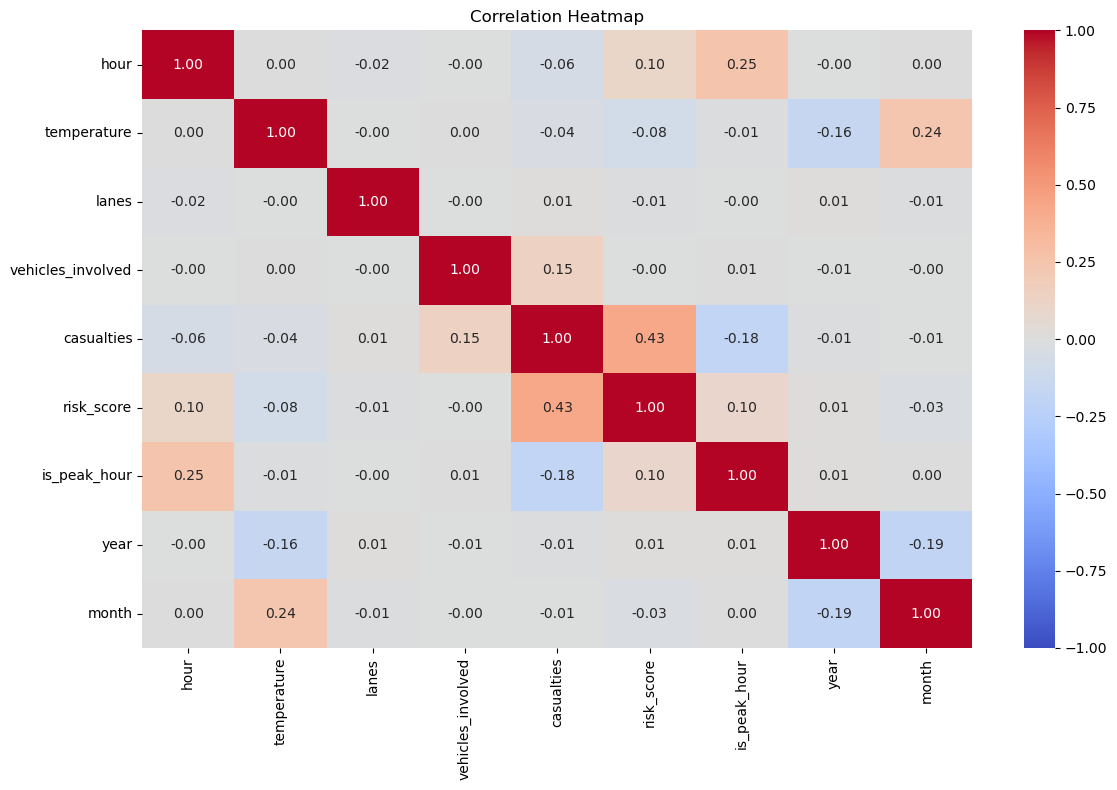

In [12]:
plt.figure(figsize=(12, 8))
corr = df[['hour', 'temperature', 'lanes', 'vehicles_involved', 'casualties', 'risk_score', 'is_peak_hour', 'year', 'month']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('charts/correlation_heatmap.png')
plt.show()

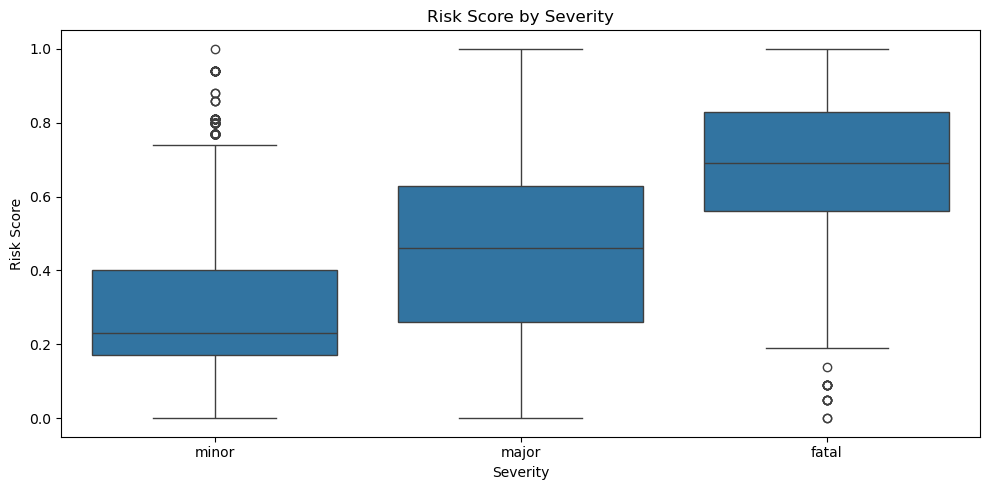

In [13]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='accident_severity', y='risk_score', order=['minor', 'major', 'fatal'])
plt.title('Risk Score by Severity')
plt.xlabel('Severity')
plt.ylabel('Risk Score')
plt.tight_layout()
plt.savefig('charts/risk_score_by_severity.png')
plt.show()

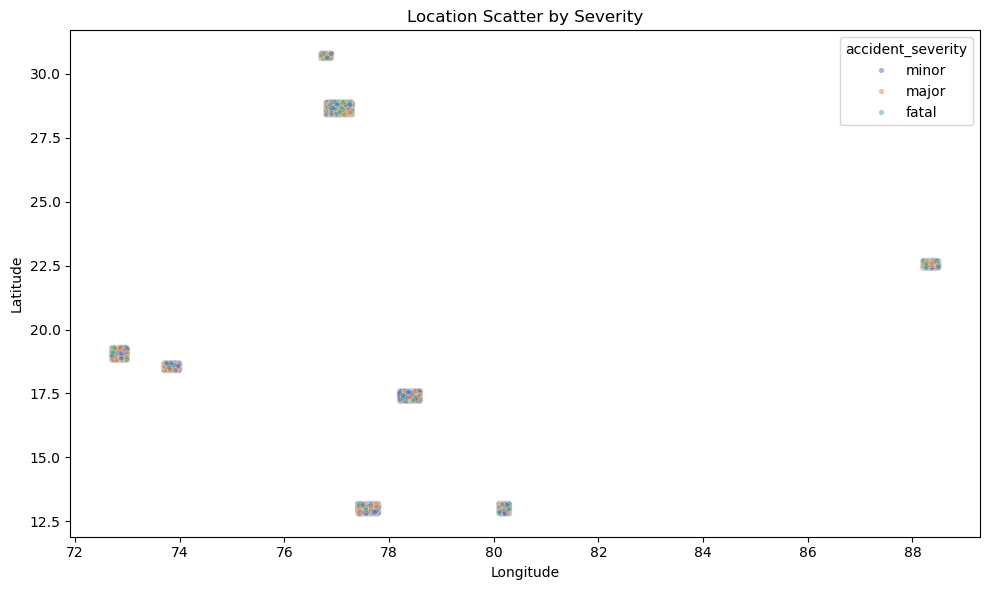

In [14]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='longitude', y='latitude', hue='accident_severity',
                hue_order=['minor', 'major', 'fatal'], palette='deep', alpha=0.5, s=15)
plt.title('Location Scatter by Severity')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.savefig('charts/location_scatter.png')
plt.show()

Insight: accident counts are flat across the 24 hours and are highest for clear weather and urban roads, simply because those are the most common conditions, so counts alone do not show danger. What changes is severity: the severity-mix chart and sections 7-8 show that night, fog and highway accidents are much more often fatal. Locations form tight clusters around the cities, so the map mostly repeats the city information.

## 6. Descriptive statistics
We compare the central tendency and spread of numeric variables and look at each severity group.

In [15]:
print(df[['temperature', 'vehicles_involved', 'lanes', 'casualties', 'risk_score']].describe())
print(df.groupby('accident_severity')[['temperature', 'casualties', 'risk_score']].mean())
print(df.groupby('accident_severity')['casualties'].agg(['mean', 'median', 'std', 'min', 'max']))

        temperature  vehicles_involved         lanes    casualties  \
count  13559.000000       13559.000000  13559.000000  13559.000000   
mean      22.744671           1.962460      3.944760      2.396563   
std        7.603561           1.059447      1.715484      1.734576   
min        8.000000           1.000000      1.000000      0.000000   
25%       16.000000           1.000000      3.000000      1.000000   
50%       23.000000           2.000000      4.000000      2.000000   
75%       29.000000           3.000000      5.000000      4.000000   
max       38.000000           5.000000      7.000000      7.000000   

         risk_score  
count  13559.000000  
mean       0.416601  
std        0.248380  
min        0.000000  
25%        0.230000  
50%        0.370000  
75%        0.630000  
max        1.000000  
                   temperature  casualties  risk_score
accident_severity                                     
fatal                22.004425    4.429204    0.637802
major 

Insight: casualties and risk score rise with severity (fatal > major > minor), while average temperature barely differs between the severity groups.

## 7. Probability and conditional risk
We calculate severity probabilities, conditional probabilities, and a simple Bayes example.

In [16]:
print(df['accident_severity'].value_counts(normalize=True))
print(pd.crosstab(df['weather'], df['accident_severity'], normalize='index'))
print(pd.crosstab(df['road_type'], df['accident_severity'], normalize='index'))
print(pd.crosstab(df['time_of_day'], df['accident_severity'], normalize='index'))
joint = pd.crosstab(df['weather'], df['accident_severity'], normalize='all')
print(joint.head())
# Bayes' theorem: P(fatal | fog) = P(fog | fatal) * P(fatal) / P(fog)
p_fatal = (df['accident_severity'] == 'fatal').mean()
p_fog = (df['weather'] == 'fog').mean()
p_fog_given_fatal = (df.loc[df['accident_severity'] == 'fatal', 'weather'] == 'fog').mean()
p_fatal_given_fog_bayes = p_fog_given_fatal * p_fatal / p_fog
p_fatal_given_fog_direct = (df.loc[df['weather'] == 'fog', 'accident_severity'] == 'fatal').mean()

print(f'P(fatal) = {p_fatal:.3f}   P(fog) = {p_fog:.3f}   P(fog | fatal) = {p_fog_given_fatal:.3f}')
print(f'P(fatal | fog) using Bayes   = {p_fatal_given_fog_bayes:.3f}')
print(f'P(fatal | fog) direct count  = {p_fatal_given_fog_direct:.3f}')

accident_severity
minor    0.450033
major    0.349952
fatal    0.200015
Name: proportion, dtype: float64
accident_severity     fatal     major     minor
weather                                        
clear              0.059452  0.288456  0.652092
fog                0.482991  0.395965  0.121044
rain               0.263107  0.425506  0.311387
accident_severity     fatal     major     minor
road_type                                      
highway            0.307368  0.401053  0.291579
rural              0.246570  0.398195  0.355235
urban              0.094221  0.287630  0.618149
accident_severity     fatal     major     minor
time_of_day                                    
Afternoon          0.103837  0.325238  0.570926
Evening            0.119134  0.355596  0.525271
Morning            0.080695  0.299796  0.619510
Night              0.400567  0.405364  0.194069
accident_severity     fatal     major     minor
weather                                        
clear              0.030386  0.

Insight: in this dataset fatal accidents are far more common in fog, at night and on highways than in clear weather, in the daytime or on urban roads (see the tables above). The Bayes calculation gives the same answer as counting directly, which confirms the probabilities are consistent.

## 8. Chi-square tests
We test whether accident severity is associated with key categorical variables such as weather, road type, visibility, and city.

In [17]:
cat_tests = ['weather', 'road_type', 'visibility', 'traffic_density', 'cause',
             'time_of_day', 'city', 'traffic_signal', 'is_weekend']

rows = []
for col in cat_tests:
    table = pd.crosstab(df['accident_severity'], df[col])
    chi2, p_value, dof, expected = stats.chi2_contingency(table)
    n = table.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    rows.append({
        'feature': col,
        'chi2': round(chi2, 1),
        'dof': dof,
        'p_value': '<0.001' if p_value < 0.001 else round(p_value, 4),
        'cramers_v': round(cramers_v, 3),
    })

chi_results = pd.DataFrame(rows).sort_values('cramers_v', ascending=False).reset_index(drop=True)
print(chi_results)

           feature    chi2  dof p_value  cramers_v
0          weather  3347.2    4  <0.001      0.351
1       visibility  3063.1    4  <0.001      0.336
2      time_of_day  2516.1    6  <0.001      0.305
3   traffic_signal   971.2    2  <0.001      0.268
4        road_type  1462.1    4  <0.001      0.232
5            cause  1411.7    8  <0.001      0.228
6  traffic_density  1199.2    4  <0.001      0.210
7             city   195.6   14  <0.001      0.085
8       is_weekend    50.2    2  <0.001      0.061


Insight: with this many rows, tiny p-values are expected, so they only show the associations are unlikely to be chance. Cramer's V shows how strong they are: weather, visibility and time of day are the strongest, while city and is_weekend are statistically significant but weak.

## 9. Preprocessing for logistic regression
We prepare the feature matrix using one-hot encoding for text columns and scaling for numeric variables.

In [18]:
LEAKAGE_COLS = ['casualties', 'risk_score']
DROP_FROM_FEATURES = (['accident_id', 'date', 'time', 'latitude', 'longitude', 'state', 'year']
                      + LEAKAGE_COLS + ['accident_severity'])
X = df.drop(columns=DROP_FROM_FEATURES)
y = df['accident_severity']
print('risk_score in model features?', 'risk_score' in X.columns)
print('casualties in model features?', 'casualties' in X.columns)
assert not set(LEAKAGE_COLS) & set(X.columns), 'a leakage column is in the model features'
print('Features used:', X.columns.tolist())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [col for col in X_train.columns if col not in num_cols]
preprocess = ColumnTransformer([('num', StandardScaler(), num_cols), ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
print('train shape', X_train.shape)
print('test shape', X_test.shape)

risk_score in model features? False
casualties in model features? False
Features used: ['city', 'hour', 'day_of_week', 'is_weekend', 'road_type', 'lanes', 'traffic_signal', 'weather', 'visibility', 'temperature', 'traffic_density', 'cause', 'vehicles_involved', 'is_peak_hour', 'month', 'time_of_day']
train shape (10847, 16)
test shape (2712, 16)


Insight: the model is trained on the circumstances printed above. casualties, risk_score and the target are excluded (checked in code), and year is left out because future years never appear in training data. cause and vehicles_involved are only known once an accident has been reported, so this model predicts severity for a reported accident, not before it happens.

## 10. Logistic Regression model
We build a baseline model, then fit the logistic regression with the prepared data.

Baseline accuracy 0.4502212389380531
Accuracy 0.819
Macro F1 0.8158
              precision    recall  f1-score   support

       fatal       0.84      0.81      0.83       542
       major       0.73      0.77      0.75       949
       minor       0.88      0.86      0.87      1221

    accuracy                           0.82      2712
   macro avg       0.82      0.81      0.82      2712
weighted avg       0.82      0.82      0.82      2712



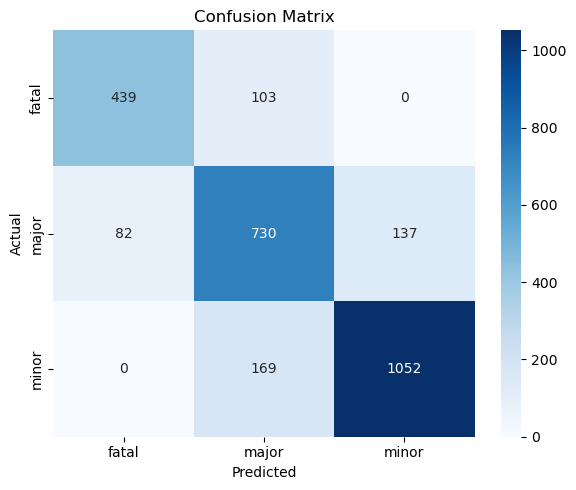

In [19]:
base_pred = y_train.value_counts().idxmax()
base_acc = accuracy_score(y_test, [base_pred] * len(y_test))
print('Baseline accuracy', base_acc)
model = Pipeline([('preprocess', preprocess), ('model', LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Accuracy', round(accuracy_score(y_test, y_pred), 4))
print('Macro F1', round(f1_score(y_test, y_pred, average='macro'), 4))
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('charts/confusion_matrix.png')
plt.show()

Insight: accuracy is far above the baseline of always predicting the most common class. The confusion matrix shows where the model gets confused, mostly around the middle class, major.

## 11. Tuning and risk factors
We try a small grid search and then inspect how each feature affects fatal risk.

In [20]:
param_grid = {'model__C': [0.01, 0.1, 1, 10, 100], 'model__class_weight': [None, 'balanced']}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(model, param_grid, cv=cv, scoring='f1_macro')
search.fit(X_train, y_train)
print(search.best_params_)
best_model = search.best_estimator_
best_pred = best_model.predict(X_test)
print('Tuned accuracy', round(accuracy_score(y_test, best_pred), 4))
print('Tuned macro F1', round(f1_score(y_test, best_pred, average='macro'), 4))
coef = best_model.named_steps['model'].coef_
feature_names = best_model.named_steps['preprocess'].get_feature_names_out()
fatal_idx = list(best_model.classes_).index('fatal')   # odds ratios for the 'fatal' class
odds = np.exp(coef[fatal_idx])
top = pd.DataFrame({'feature': feature_names, 'odds_ratio': odds}).sort_values('odds_ratio', ascending=False).head(10)
print(top)

{'model__C': 10, 'model__class_weight': None}
Tuned accuracy 0.8193
Tuned macro F1 0.8161
                     feature  odds_ratio
43    cat__time_of_day_Night   12.425923
36  cat__cause_drunk driving    8.856579
37   cat__cause_overspeeding    5.759181
27          cat__weather_fog    5.658916
30       cat__visibility_low    4.678807
23    cat__road_type_highway    3.711778
5     num__vehicles_involved    3.193346
33  cat__traffic_density_low    2.113066
11           cat__city_Delhi    2.057512
13         cat__city_Kolkata    1.503398


Insight: tuning changes the scores only slightly, so the default model is already close to the best this feature set can do. The features with the highest odds ratios are the ones most strongly linked to fatal outcomes in this dataset (numeric features: per +1 standard deviation). This is association, not proof of cause.

In [21]:
# Robustness check: use only information that is known BEFORE an accident happens
post_event_cols = ['cause', 'vehicles_involved']
X_pre = X.drop(columns=post_event_cols)
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_pre, y, test_size=0.2, random_state=42, stratify=y)

num_pre = Xp_train.select_dtypes(include=[np.number]).columns.tolist()
cat_pre = [col for col in Xp_train.columns if col not in num_pre]
pre_model = Pipeline([
    ('preprocess', ColumnTransformer([
        ('num', StandardScaler(), num_pre),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_pre),
    ])),
    ('model', LogisticRegression(max_iter=1000)),
])
pre_model.fit(Xp_train, yp_train)
pre_pred = pre_model.predict(Xp_test)
print('Accuracy without cause and vehicles_involved:', round(accuracy_score(yp_test, pre_pred), 4))
print('Macro F1 without them:', round(f1_score(yp_test, pre_pred, average='macro'), 4))

Accuracy without cause and vehicles_involved: 0.7091
Macro F1 without them: 0.6985


Insight: cause and vehicles_involved are only known after an accident, so this run shows how much of the accuracy comes from them. Compare it with the accuracy above.

In [22]:
def predict_scenario(**changes):
    """Start from a real row (so every model column exists), change some values, predict."""
    row = X_train.iloc[[0]].copy()
    for col, value in changes.items():
        assert col in row.columns, f'{col} is not a model feature'
        row[col] = value
    pred = best_model.predict(row)[0]
    proba = pd.Series(best_model.predict_proba(row)[0], index=best_model.classes_).round(3)
    return pred, proba

high_risk = dict(city='Delhi', day_of_week='Monday', is_weekend=0, road_type='highway', lanes=4,
                 traffic_signal=0, weather='fog', visibility='low', temperature=27,
                 traffic_density='low', cause='drunk driving', vehicles_involved=2,
                 is_peak_hour=0, hour=3, time_of_day='Night', month=7)
low_risk = dict(city='Delhi', day_of_week='Monday', is_weekend=0, road_type='urban', lanes=4,
                traffic_signal=1, weather='clear', visibility='high', temperature=27,
                traffic_density='high', cause='distraction', vehicles_involved=1,
                is_peak_hour=1, hour=14, time_of_day='Afternoon', month=7)

for name, case in [('High-risk scenario', high_risk), ('Low-risk scenario', low_risk)]:
    pred, proba = predict_scenario(**case)
    print(name, '-> predicted severity:', pred)
    print(proba.to_string())
    print()

High-risk scenario -> predicted severity: fatal
fatal    1.0
major    0.0
minor    0.0

Low-risk scenario -> predicted severity: minor
fatal    0.0
major    0.0
minor    1.0



## 12. Conclusion and summary
We list the main findings and save the report.

In [23]:
def fatal_share(mask):
    return (df.loc[mask, 'accident_severity'] == 'fatal').mean()

overall = (df['accident_severity'] == 'fatal').mean()
top_features = ', '.join(top['feature'].str.replace(r'^(cat|num)__', '', regex=True).head(5))

summary = [
    f'Data: {len(df)} accidents after cleaning; columns dropped for more than {MISSING_LIMIT}% missing values: {cols_to_drop}.',
    f'Fatal share: overall {overall:.1%}; fog {fatal_share(df["weather"] == "fog"):.1%} vs clear {fatal_share(df["weather"] == "clear"):.1%}.',
    f'Fatal share: night {fatal_share(df["time_of_day"] == "Night"):.1%} vs other times {fatal_share(df["time_of_day"] != "Night"):.1%}.',
    f'Fatal share: highway {fatal_share(df["road_type"] == "highway"):.1%} vs urban {fatal_share(df["road_type"] == "urban"):.1%}.',
    f'Model: baseline accuracy {base_acc:.1%}; logistic regression {accuracy_score(y_test, y_pred):.1%}; tuned {accuracy_score(y_test, best_pred):.1%}.',
    f'Features most strongly linked to fatal outcomes in the model: {top_features}.',
]

with open('results_summary.txt', 'w', encoding='utf-8') as f:
    for line in summary:
        f.write(line + '\n')

print('\n'.join(summary))
print('Saved results_summary.txt')

Data: 13559 accidents after cleaning; columns dropped for more than 50% missing values: ['festival'].
Fatal share: overall 20.0%; fog 48.3% vs clear 5.9%.
Fatal share: night 40.1% vs other times 9.8%.
Fatal share: highway 30.7% vs urban 9.4%.
Model: baseline accuracy 45.0%; logistic regression 81.9%; tuned 81.9%.
Features most strongly linked to fatal outcomes in the model: time_of_day_Night, cause_drunk driving, cause_overspeeding, weather_fog, visibility_low.
Saved results_summary.txt
